# Experiment 07: Decision Tree Classification

## Aim
To implement a Decision Tree classifier and evaluate its performance on a classification dataset.

## Dataset and source
- **Dataset:** Breast Cancer Wisconsin Diagnostic
- **Source:** Built into `scikit-learn` (`sklearn.datasets.load_breast_cancer`)
- **Size:** 569 samples and 30 numeric features
- **Classes:** malignant and benign
- **Download required:** No Kaggle download is required. The dataset is bundled with scikit-learn.

## Theory
A Decision Tree is a supervised learning algorithm that predicts a class by repeatedly splitting the data using feature-based rules. At each node, the algorithm selects a split that improves class purity. Common split criteria include **Gini impurity** and **entropy**.

For a node with class proportions \(p_1, p_2, \ldots, p_k\), Gini impurity is:

\[
Gini = 1 - \sum_{i=1}^{k} p_i^2
\]

A tree can overfit if it grows too deep. The `max_depth` parameter limits its depth and can help control complexity.

## Algorithm
1. Load the Breast Cancer Wisconsin dataset.
2. Separate the feature matrix `X` and target labels `y`.
3. Split the data into training and testing sets.
4. Create a Decision Tree using the Gini criterion and a maximum depth of 4.
5. Train the model on the training set.
6. Predict the test labels and evaluate accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.
7. Visualize the tree, confusion matrix, ROC curve, and important features.


## Program
The following cell contains the complete executable program.

Dataset: Breast Cancer Wisconsin Diagnostic
Dataset source: scikit-learn built-in dataset
Number of rows: 569
Number of features: 30
Class labels: {0: np.str_('malignant'), 1: np.str_('benign')}

Class distribution:
target
malignant    212
benign       357
Name: count, dtype: int64

Model: DecisionTreeClassifier(criterion='gini', max_depth=4)
Training samples: 455
Testing samples: 114
Accuracy: 0.9386 (93.86%)

Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114

Confusion Matrix:
[[39  3]
 [ 4 68]]
ROC-AUC: 0.9342


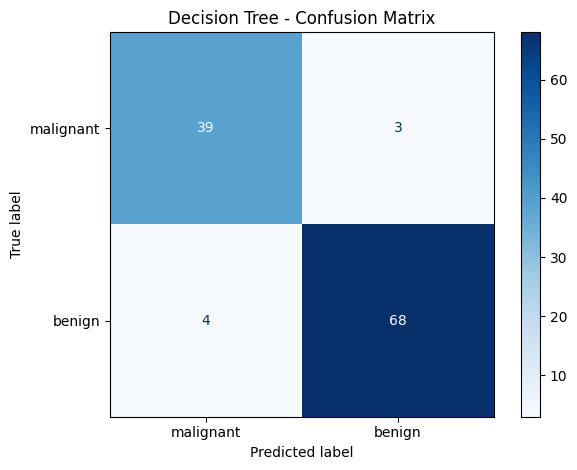

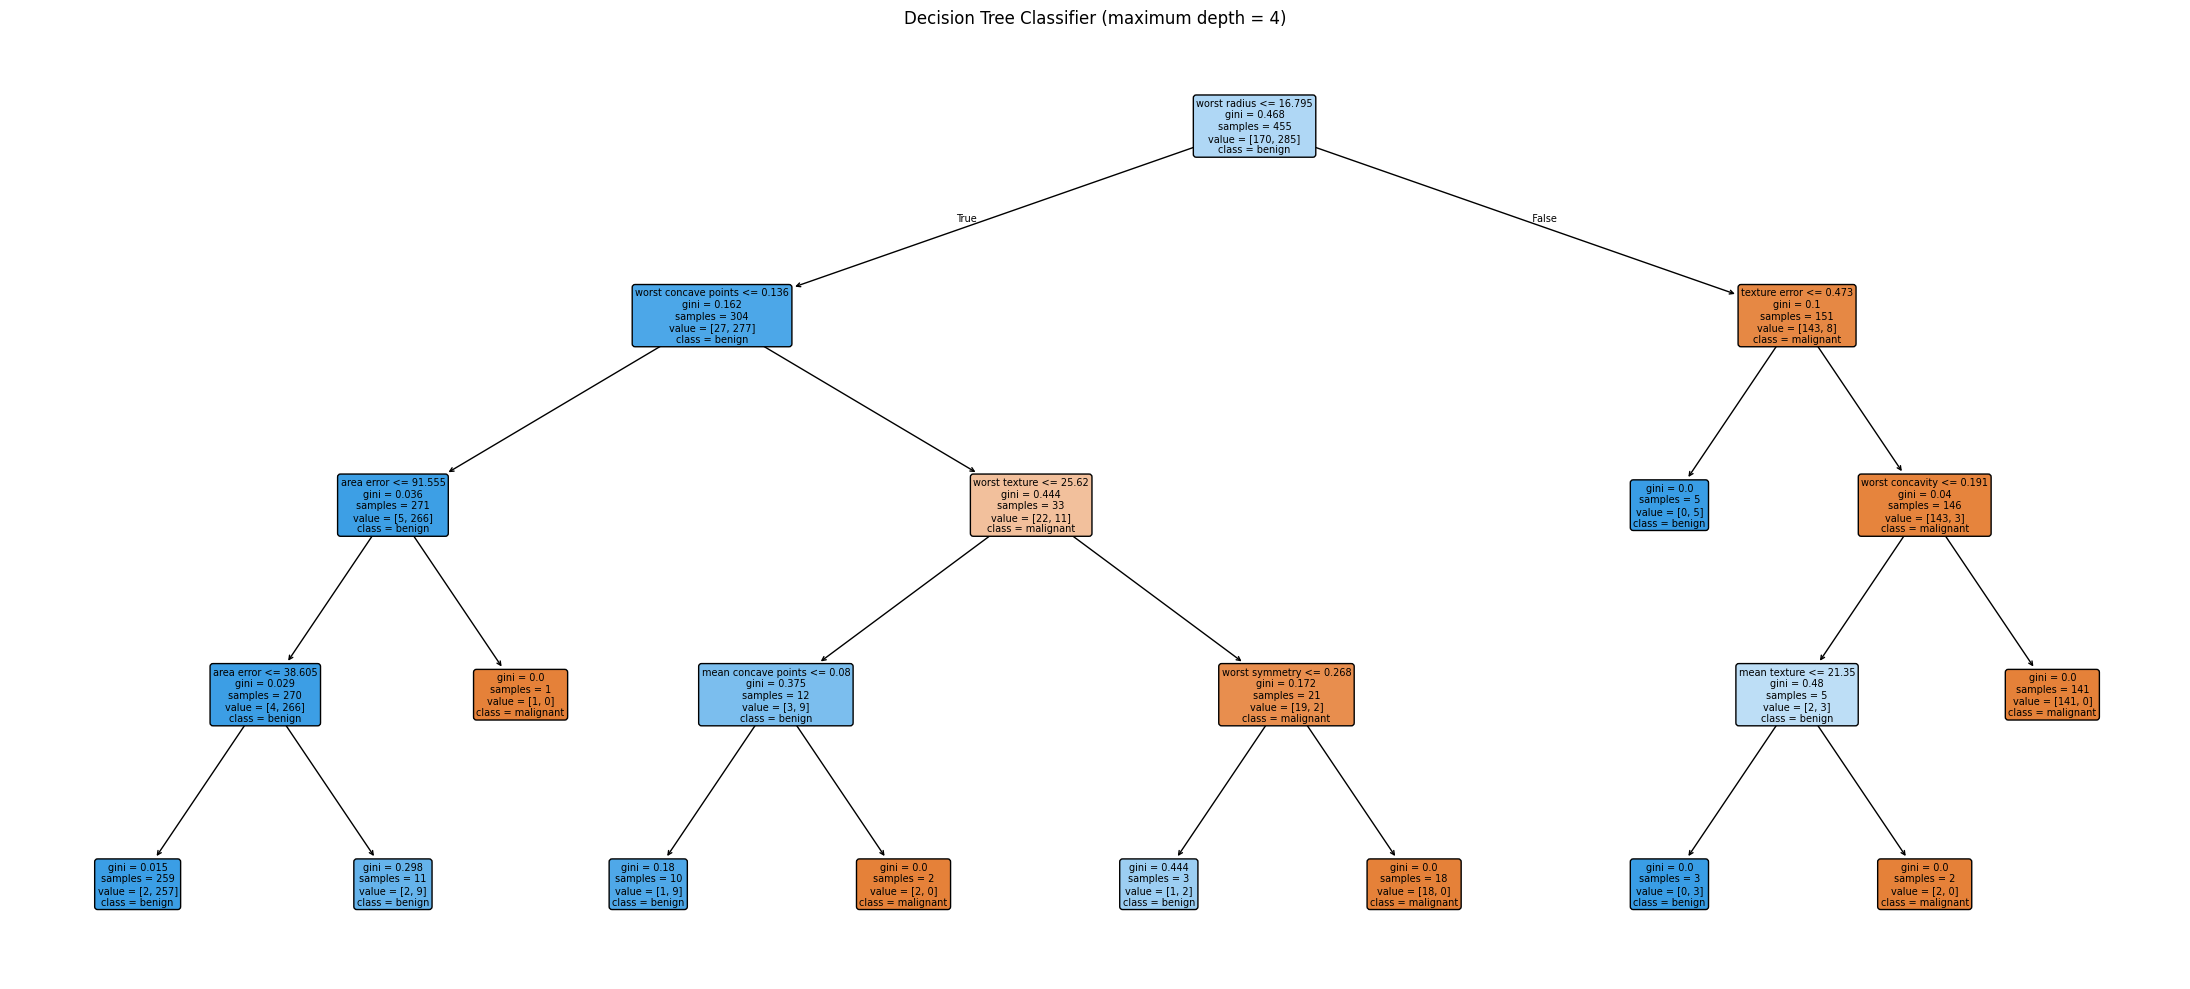

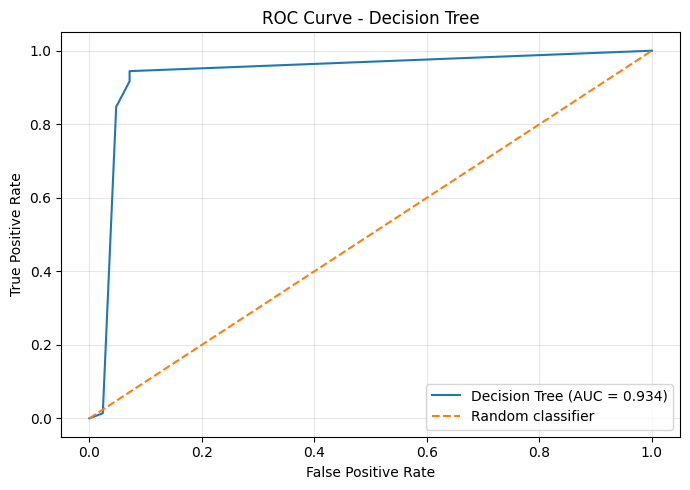


Top 10 Feature Importances:
worst radius            0.7335
worst concave points    0.1220
texture error           0.0458
worst texture           0.0323
worst concavity         0.0172
mean concave points     0.0133
area error              0.0127
mean texture            0.0118
worst symmetry          0.0113
mean area               0.0000
dtype: float64


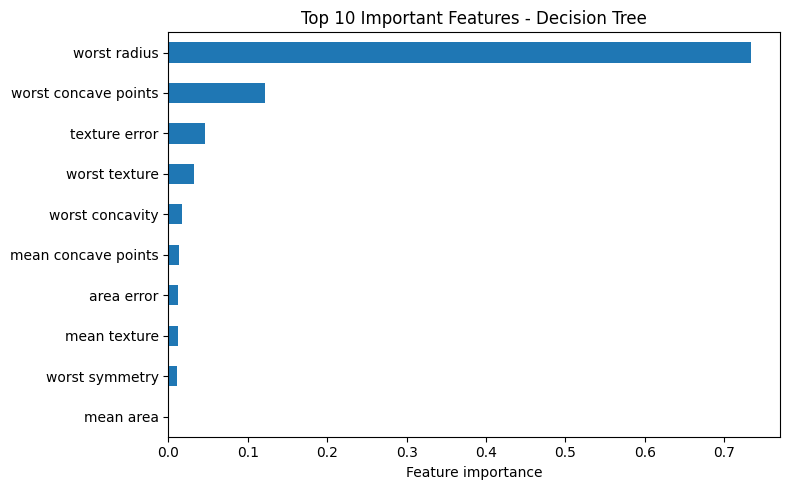


Sample prediction:
Predicted class: malignant
Actual class:    malignant


In [1]:
"""
Experiment 07: Decision Tree Classification
Dataset: Breast Cancer Wisconsin Diagnostic (built into scikit-learn)
Rows: 569 | Features: 30
"""

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score
)

# 1. Load the built-in dataset (no Kaggle download required)
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
target_names = data.target_names

print("Dataset: Breast Cancer Wisconsin Diagnostic")
print("Dataset source: scikit-learn built-in dataset")
print(f"Number of rows: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print("Class labels:", dict(enumerate(target_names)))
print("\nClass distribution:")
print(y.value_counts().sort_index().rename(index=dict(enumerate(target_names))))

# 2. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Create and train the Decision Tree model
# max_depth limits complexity; random_state makes results reproducible.
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)
model.fit(X_train, y_train)

# 4. Predict test labels and probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 5. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print("\nModel: DecisionTreeClassifier(criterion='gini', max_depth=4)")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

# 6. Visualize the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=target_names, cmap="Blues", values_format="d"
)
plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

# 7. Plot the trained decision tree
plt.figure(figsize=(22, 10))
plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=list(target_names),
    filled=True,
    rounded=True,
    fontsize=7
)
plt.title("Decision Tree Classifier (maximum depth = 4)")
plt.tight_layout()
plt.show()

# 8. Plot ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 9. Display feature importance
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 10 Feature Importances:")
print(importance.head(10).round(4))

importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("Feature importance")
plt.title("Top 10 Important Features - Decision Tree")
plt.tight_layout()
plt.show()

# 10. Demonstrate a prediction for one test sample
sample = X_test.iloc[[0]]
prediction = model.predict(sample)[0]
print("\nSample prediction:")
print("Predicted class:", target_names[prediction])
print("Actual class:   ", target_names[y_test.iloc[0]])


## Expected output
The program prints the dataset size, class distribution, train/test sample counts, accuracy, classification report, confusion matrix, ROC-AUC, top feature importances, and one sample prediction. It also displays four visualizations: the confusion matrix, decision tree, ROC curve, and top feature importances.

Exact metrics can vary slightly across scikit-learn versions, but with `random_state=42` the split and tree are reproducible within a given version.

## Result
The Decision Tree classifier was trained and evaluated on the Breast Cancer Wisconsin Diagnostic dataset. Its performance was assessed using classification metrics and visualizations.

## Viva-voce questions and answers

**1. What is a Decision Tree?**  
A supervised learning algorithm that predicts an output by following a sequence of feature-based decision rules arranged as a tree.

**2. What are the main components of a Decision Tree?**  
Root node, decision/internal nodes, branches, and leaf nodes.

**3. What is Gini impurity?**  
A measure of how mixed the classes are at a node. A value of 0 means the node contains only one class.

**4. What is entropy?**  
A measure of uncertainty or impurity in a node, commonly used with information gain to choose splits.

**5. What is overfitting in a Decision Tree?**  
It occurs when a tree learns training data too closely, including noise, and performs poorly on unseen data.

**6. How can overfitting be reduced?**  
Limit `max_depth`, increase `min_samples_split` or `min_samples_leaf`, or prune the tree.

**7. Does a Decision Tree require feature scaling?**  
Usually no. Tree splits depend on feature thresholds, so standardization is generally unnecessary.

**8. What is feature importance?**  
A score estimating how much a feature contributes to reducing impurity across the tree.

**9. What is the difference between classification and regression trees?**  
Classification trees predict categorical classes; regression trees predict continuous numeric values.

**10. Why is the dataset split into training and testing sets?**  
To evaluate how well the model generalizes to unseen data rather than only measuring its performance on training examples.
